# Lab: Losing Orthogonality
**Math 189M — Numerical Linear Algebra**

In exact arithmetic, Gram-Schmidt, Householder QR, and Cholesky of $A^\top A$ all produce the same upper triangular factor $\hat R$. In floating point they behave very differently. Here we measure two things for each algorithm:

$$\text{residual} = \frac{\|A-\hat Q\hat R\|_2}{\|A\|_2}, \qquad \text{loss of orthogonality} = \|I-\hat Q^\top\hat Q\|_2 .$$

In [9]:
using LinearAlgebra, Plots, Printf, Random
Random.seed!(189)
const ε = eps(Float64)

2.220446049250313e-16

## Step 1: Classical and modified Gram-Schmidt

At step $k$, start with $v^{(0)}=a_k$ and orthogonalize against $q_1,\dots,q_{k-1}$ one at a time. The two methods differ only in how $r_{jk}$ is computed:

- **CGS:** $r_{jk}=q_j^\top a_k$ (the original column)
- **MGS:** $r_{jk}=q_j^\top v^{(j-1)}$ (the partially orthogonalized vector)

> These implementations follow the recursion on the lecture slides. If your class-notes versions differ in style, paste them over these; the interface `Q, R = cgs(A)` is what the rest of the notebook uses.

In [10]:
function cgs(A)
    m, n = size(A)
    Q = zeros(m, n)
    R = zeros(n, n)
    for k in 1:n
        v = A[:, k]
        for j in 1:k-1
            R[j, k] = Q[:, j]' * A[:, k]     # uses the ORIGINAL column
        end
        for j in 1:k-1
            v = v - R[j, k] * Q[:, j]
        end
        R[k, k] = norm(v)
        Q[:, k] = v / R[k, k]
    end
    return Q, R
end

function mgs(A)
    m, n = size(A)
    Q = zeros(m, n)
    R = zeros(n, n)
    for k in 1:n
        v = A[:, k]
        for j in 1:k-1
            R[j, k] = Q[:, j]' * v           # uses the PARTIALLY orthogonalized vector
            v = v - R[j, k] * Q[:, j]
        end
        R[k, k] = norm(v)
        Q[:, k] = v / R[k, k]
    end
    return Q, R
end

mgs (generic function with 1 method)

Test on the $3\times 3$ in-class hand example. The by-hand answer is $\hat R=\begin{bmatrix}3&3&6\\0&3&3\\0&0&3\end{bmatrix}$.

In [11]:
A3 = [2.0 0 3; 2 3 3; 1 3 6]
R_hand = [3.0 3 6; 0 3 3; 0 0 3]

for (name, f) in (("CGS", cgs), ("MGS", mgs))
    Q, R = f(A3)
    @printf("%s:  ‖R - R_hand‖ = %.2e,   ‖A - QR‖ = %.2e,   ‖I - QᵀQ‖ = %.2e\n",
            name, norm(R - R_hand), norm(A3 - Q*R), norm(I - Q'*Q))
end
Q, R = mgs(A3)
R

CGS:  ‖R - R_hand‖ = 0.00e+00,   ‖A - QR‖ = 0.00e+00,   ‖I - QᵀQ‖ = 1.97e-16
MGS:  ‖R - R_hand‖ = 0.00e+00,   ‖A - QR‖ = 0.00e+00,   ‖I - QᵀQ‖ = 1.97e-16


3×3 Matrix{Float64}:
 3.0  3.0  6.0
 0.0  3.0  3.0
 0.0  0.0  3.0

**Your answer:** Does $\hat R$ match your hand computation? (Replace this text.)

## Step 2: Test matrices with a prescribed condition number

Take $A=U\Sigma V^\top$ with $U\in\mathbb R^{m\times n}$, $V\in\mathbb R^{n\times n}$ having orthonormal columns and singular values $\sigma_i$ spaced logarithmically from $1$ down to $1/\kappa$.

In [12]:
function testmatrix(m, n, kappa)
    U = Matrix(qr(randn(m, n)).Q)             # m×n, orthonormal columns
    V = Matrix(qr(randn(n, n)).Q)             # n×n orthogonal
    σ = 10 .^ range(0, -log10(kappa), length=n)
    return U * Diagonal(σ) * V'
end

for κ in (1e2, 1e6, 1e10)
    A = testmatrix(100, 20, κ)
    @printf("requested κ = %.1e,  cond(A) = %.4e\n", κ, cond(A))
end

requested κ = 1.0e+02,  cond(A) = 1.0000e+02
requested κ = 1.0e+06,  cond(A) = 1.0000e+06
requested κ = 1.0e+10,  cond(A) = 1.0000e+10


## Step 3: Residual and loss of orthogonality versus $\kappa$

For $m=100$, $n=20$, $\kappa=10^1,\dots,10^{15}$, compare CGS, MGS, and Householder QR (Julia's `qr`).

In [13]:
resid(A, Q, R) = opnorm(A - Q*R) / opnorm(A)
orthloss(Q)    = opnorm(I - Q'*Q)

function householder(A)
    F = qr(A)
    return Matrix(F.Q), Matrix(F.R)           # thin factors
end

m, n = 100, 20
κs = 10.0 .^ (1:15)
methods = [("CGS", cgs), ("MGS", mgs), ("Householder", householder)]

res_data = Dict(name => Float64[] for (name, _) in methods)
orth_data = Dict(name => Float64[] for (name, _) in methods)

for κ in κs
    A = testmatrix(m, n, κ)
    for (name, f) in methods
        Q, R = f(A)
        push!(res_data[name],  resid(A, Q, R))
        push!(orth_data[name], orthloss(Q))
    end
end

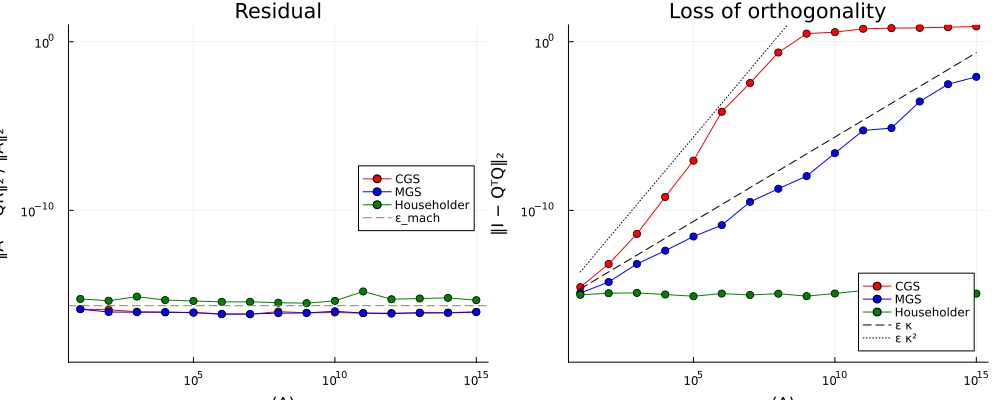

In [14]:
floor(x) = max.(x, 1e-19)      # keep exact zeros from breaking the log plot
colors = Dict("CGS" => :red, "MGS" => :blue, "Householder" => :green)

p1 = plot(xscale=:log10, yscale=:log10, xlabel="κ(A)", ylabel="‖A − QR‖₂ / ‖A‖₂",
          title="Residual", legend=:right, ylims=(1e-19, 1e1))
for (name, _) in methods
    plot!(p1, κs, floor(res_data[name]), label=name, marker=:circle, color=colors[name])
end
hline!(p1, [ε], label="ε_mach", linestyle=:dash, color=:gray)

p2 = plot(xscale=:log10, yscale=:log10, xlabel="κ(A)", ylabel="‖I − QᵀQ‖₂",
          title="Loss of orthogonality", legend=:bottomright, ylims=(1e-19, 1e1))
for (name, _) in methods
    plot!(p2, κs, floor(orth_data[name]), label=name, marker=:circle, color=colors[name])
end
plot!(p2, κs, ε .* κs,    label="ε κ",  linestyle=:dash, color=:black)
plot!(p2, κs, ε .* κs.^2, label="ε κ²", linestyle=:dot,  color=:black)

plot(p1, p2, layout=(1, 2), size=(1000, 400))

## Step 4: Interpretation

**Your answer:** Which methods have a residual near $\varepsilon_{\text{mach}}$ for all $\kappa$? How does the loss of orthogonality for each method scale with $\kappa$? What happens to CGS when $\kappa$ is large? (Replace this text.)

## Step 5: Least squares three ways

Fit a degree-11 polynomial using the Vandermonde matrix ($m=100$, $n=12$) with noisy data, and compare:

1. normal equations with `cholesky`,
2. MGS with $\hat R x=\hat Q^\top b$,
3. Householder QR via backslash,

against a `BigFloat` Householder reference.

In [15]:
m, n = 100, 12
t = range(0, 1, length=m)
A = [ti^(j-1) for ti in t, j in 1:n]
xtrue = ones(n)
b = A * xtrue + 0.01 * randn(m)

κA = cond(A)
@printf("κ₂(A) = %.3e,   κ₂(A)² = %.3e,   1/ε = %.3e\n", κA, κA^2, 1/ε)

κ₂(A) = 1.206e+08,   κ₂(A)² = 1.455e+16,   1/ε = 4.504e+15


In [16]:
# (i) normal equations + Cholesky
x_chol = try
    cholesky(Symmetric(A' * A)) \ (A' * b)
catch err
    nothing
end

# (ii) MGS with explicit Qᵀb
Qm, Rm = mgs(A)
x_mgs = UpperTriangular(Rm) \ (Qm' * b)

# (iii) Householder QR (backslash)
x_hh = A \ b

# BigFloat reference (Householder QR in 256-bit arithmetic)
x_ref = setprecision(256) do
    Ab = BigFloat.(A)
    bb = BigFloat.(b)
    F = qr(Ab)
    F \ bb
end

relerr(x) = x === nothing ? nothing :
    Float64(setprecision(256) do
        norm(BigFloat.(x) - x_ref) / norm(x_ref)
    end)

results = [("Normal eq. + Cholesky", relerr(x_chol)),
           ("MGS (explicit Qᵀb)",    relerr(x_mgs)),
           ("Householder (A \\ b)",   relerr(x_hh))]

println("κ₂(A)  = ", @sprintf("%.3e", κA))
println("κ₂(A)² = ", @sprintf("%.3e", κA^2))
println()
@printf("%-26s %s\n", "Method", "Relative error")
println("-"^46)
for (name, e) in results
    if e === nothing
        @printf("%-26s %s\n", name, "cholesky failed (not numerically PD)")
    else
        @printf("%-26s %.3e\n", name, e)
    end
end

κ₂(A)  = 1.206e+08
κ₂(A)² = 1.455e+16

Method                     Relative error
----------------------------------------------
Normal eq. + Cholesky      2.932e-02
MGS (explicit Qᵀb)         5.499e-07
Householder (A \ b)        5.176e-09


**Your answer:** Which method has the smallest error, and how do the errors relate to $\kappa_2(A)$ and $\kappa_2(A)^2$? (Replace this text.)

*Tip:* the noise is random, so rerun a few times (or change the seed) to see how stable your conclusions are.

## Step 6 (Ungraded but important for comprehension check)

How does this lab connect to the course material? What is your takeaway? (Replace this text.)